# 1. Local convergence: gap and dimension

Clean version of the current experiment. Run cells from top to bottom. Original notebooks are unchanged.

The factor $q_0=1-\delta/((d-1)\Delta)$ is a limiting local reference, not a proved finite-region or global error bound.


This notebook tests the conditional/local expectation bound for the random-plane
operator-norm algorithm. It deliberately starts inside the contracting region,
separating this experiment from the global entrance-time question.

Write $M=A^\top A$, $\lambda_1>\lambda_2\ge\cdots\ge\lambda_d$,
$\delta=\lambda_1-\lambda_2$, $\Delta=\lambda_1-\lambda_d$, and
$\varepsilon_k=\lambda_1-\|Av^k\|^2$.
For $\varepsilon_0\le\eta\delta$, the bound is
$$\mathbb E[\varepsilon_k]\le q_\eta^k\mathbb E[\varepsilon_0],\qquad
q_\eta=1-\frac{(1-\eta)\delta}{(d-1)\Delta}.$$

In [14]:
from pathlib import Path
import sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

from operator_norm import (
    estimate_operator_norm, controlled_spectrum, local_initial_vectors,
    diagonal_ensemble, rate_constants, global_bound,
    bootstrap_mean_band, fitted_mean_rate,
)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'font.size': 10, 'savefig.bbox': 'tight'})
# LaTeX-style text without requiring a local TeX installation. Set this to
# True only if a working LaTeX distribution is installed on your machine.
USE_SYSTEM_LATEX = False
HERE = Path.cwd()
import matplotlib as mpl
mpl.rcParams.update({
    'text.usetex': USE_SYSTEM_LATEX,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
    'figure.dpi': 120,
    'savefig.dpi': 200,
})
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__,
      '| SciPy:', scipy.__version__, '| Matplotlib:', matplotlib.__version__)

Python: 3.14.7 | NumPy: 2.5.2 | SciPy: 1.18.1 | Matplotlib: 3.11.1


In [15]:
# Preserve the current spectral-gap colors (quick and full profiles).
colors = ['darkblue', 'orange', 'green', 'red']


## Controlled spectra and initialization

Set $\lambda_1=1$, $\lambda_2=1-g$, and keep the lower eigenvalues fixed in
$[0,1/2]$, including $\lambda_d=0$. Thus $\Delta=1$ and $\delta/\Delta=g$.
Use $A=\operatorname{diag}(\sqrt{\lambda_i})$. Rotating its right singular basis
would not change the distribution of this rotationally invariant algorithm.

Initialize every independent trajectory at
$$v^0=\sqrt{1-\eta/2}\,u_1+\sqrt{\eta/2}\,u_2,$$
so $\varepsilon_0=\eta\delta/2$. Only the search randomness differs between runs.
The ensemble implementation batches these independent copies; it does not use
multiple directions for one algorithmic step.

The budget targets four theoretical time units, subject to an explicit cap.
A capped configuration is a shorter observation, not evidence of convergence.

In [17]:
PROFILE = 'quick'  # 'quick' or 'full'; existing matching .npz files are reused.
ETAS = [0.01, 0.1, 0.5]
SEED = 20260917
SETTINGS = {
    'quick': dict(dimensions=[20, 60], gaps=[.5, .1, .03], runs=96, cap=2500, bootstrap=150),
    'full': dict(dimensions=[20, 100, 500], gaps=[.5, .1, .03, .01], runs=500, cap=100000, bootstrap=500),
}
assert len(set(ETAS)) == len(ETAS) and all(0 < eta < 1 for eta in ETAS)
cfg = SETTINGS[PROFILE]
ETA_TAG = 'etas_' + '_'.join(f'{eta:g}' for eta in ETAS)
CACHE = HERE / 'results' / '01_local' / PROFILE / ETA_TAG
OUT = HERE / 'results' / '01_local' / PROFILE / ETA_TAG
OUT.mkdir(parents=True, exist_ok=True)
FIT_WINDOW = (1e-4, .5)
MAX_FIT_POINTS = 400
MAX_CURVE_POINTS = 320
from matplotlib.lines import Line2D
import csv

gap_colors = {g: colors[i % len(colors)] for i, g in enumerate(cfg['gaps'])}
dim_styles = dict(zip(cfg['dimensions'], ['-', '--', ':', '-.']))
dim_markers = dict(zip(cfg['dimensions'], ['o', 's', '^', 'D']))
dim_colors = dict(zip(cfg['dimensions'], ['#0072B2', '#D55E00', '#009E73', '#CC79A7']))
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.alpha': .17, 'axes.titlepad': 10,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})

def summarize_ensemble(E, *, seed, resamples):
    """Resample complete trajectories; release full histories after each case.

    Fit the log arithmetic mean on a fixed window selected from the original
    ensemble. Bootstrap intervals are conditional on that declared window.
    At most 400 uniformly spaced eligible iterations are used in each fit.
    This is an observation-window rate, not a universal asymptotic rate.
    """
    mean = E.mean(axis=0)
    e0 = float(mean[0])
    ratio = mean / e0
    eligible = np.flatnonzero((ratio >= FIT_WINDOW[0]) & (ratio <= FIT_WINDOW[1]))
    fit_idx = eligible[np.unique(np.linspace(0, len(eligible)-1,
                         min(MAX_FIT_POINTS, len(eligible)), dtype=int))] if len(eligible) else eligible
    curve_idx = np.unique(np.r_[np.linspace(0, E.shape[1]-1,
                              min(MAX_CURVE_POINTS, E.shape[1]), dtype=int), fit_idx])
    sample = np.array(E[:, curve_idx], copy=True)
    weights = np.random.default_rng(seed).multinomial(
        len(E), np.full(len(E), 1 / len(E)), size=resamples)
    boot_mean = weights @ sample / len(E)
    low, high = np.quantile(boot_mean, [.025, .975], axis=0)
    rate = rate_low = rate_high = np.nan
    fit_start = fit_end = None
    if len(fit_idx) >= 10:
        fit_start, fit_end = int(fit_idx[0]), int(fit_idx[-1])
        centered_k = fit_idx.astype(float) - fit_idx.mean()
        denom = centered_k @ centered_k
        rate = float(-(np.log(mean[fit_idx]) @ centered_k) / denom)
        boot_rate = -(np.log(np.maximum(boot_mean[:, np.searchsorted(curve_idx, fit_idx)],
                              np.finfo(float).tiny)) @ centered_k) / denom
        rate_low, rate_high = np.quantile(boot_rate, [.025, .975])
    return dict(k=curve_idx, mean=ratio[curve_idx], low=low/e0, high=high/e0,
                e0=e0, rate=rate, rate_low=float(rate_low), rate_high=float(rate_high),
                fit_start=fit_start, fit_end=fit_end, fit_points=len(fit_idx),
                observed_steps=E.shape[1]-1, runs=E.shape[0])

print('Settings:', cfg)
experiments = []
for eta_index, ETA in enumerate(ETAS):
    for case, (d, gap) in enumerate((d,g) for d in cfg['dimensions'] for g in cfg['gaps']):
        lam = controlled_spectrum(d, gap)
        constants = rate_constants(lam, ETA)
        target = int(np.ceil(4 / (-constants['logq'])))
        steps = min(target, cfg['cap'])
        cache_file = CACHE / f'd{d}_g{gap:g}_eta_{ETA:g}.npz'
        if cache_file.exists():
            with np.load(cache_file) as saved:
                if not np.allclose(saved['lambdas'], lam) or not np.isclose(float(saved['eta']), ETA):
                    raise ValueError(f'Cache parameters differ: {cache_file}')
                if int(saved['seed']) != SEED + case:
                    raise ValueError(f'Cache seed differs: {cache_file}')
                E = saved['errors']
            if E.shape != (cfg['runs'], steps + 1):
                raise ValueError(f'Cache shape {E.shape} differs from requested settings: {cache_file}')
            origin = 'cached'
        else:
            E = diagonal_ensemble(lam, runs=cfg['runs'], steps=steps, seed=SEED+case,
                 initial=local_initial_vectors(lam, cfg['runs'], ETA), eta=ETA)['errors']
            np.savez_compressed(cache_file, errors=E, lambdas=lam, eta=ETA, seed=SEED+case)
            origin = 'simulated'
        assert np.all(E[:, 0] <= ETA*constants['delta']*(1+1e-12))
        for left in range(0, E.shape[1]-1, 4096):
            assert np.max(np.diff(E[:, left:left+4097], axis=1)) < 1e-11
        summary = summarize_ensemble(E, seed=SEED+1000+eta_index*100+case,
                                     resamples=cfg['bootstrap'])
        experiments.append(dict(d=d, gap=gap, eta=ETA, constants=constants,
                                capped=steps<target, **summary))
        del E
        print(f'{origin}: eta={ETA:g}, d={d}, g={gap:g}, steps={steps}, '
              f'capped={steps<target}, fit={summary["rate"]:.4g}', flush=True)

Settings: {'dimensions': [20, 60], 'gaps': [0.5, 0.1, 0.03], 'runs': 96, 'cap': 2500, 'bootstrap': 150}
simulated: eta=0.01, d=20, g=0.5, steps=152, capped=False, fit=0.05058
simulated: eta=0.01, d=20, g=0.1, steps=766, capped=False, fit=0.01633
simulated: eta=0.01, d=20, g=0.03, steps=2500, capped=True, fit=0.005017
simulated: eta=0.01, d=60, g=0.5, steps=475, capped=False, fit=0.01601
simulated: eta=0.01, d=60, g=0.1, steps=2382, capped=False, fit=0.004706
simulated: eta=0.01, d=60, g=0.03, steps=2500, capped=True, fit=0.001425
simulated: eta=0.1, d=20, g=0.5, steps=167, capped=False, fit=0.05101
simulated: eta=0.1, d=20, g=0.1, steps=843, capped=False, fit=0.01631
simulated: eta=0.1, d=20, g=0.03, steps=2500, capped=True, fit=0.005011
simulated: eta=0.1, d=60, g=0.5, steps=523, capped=False, fit=0.0161
simulated: eta=0.1, d=60, g=0.1, steps=2500, capped=True, fit=0.0047
simulated: eta=0.1, d=60, g=0.03, steps=2500, capped=True, fit=0.001416
simulated: eta=0.5, d=20, g=0.5, steps=302

## Mean-error curves and limiting local reference (eta = 0)

The simulation still uses the original initializations eta=0.01, 0.1 and 0.5.
Only the plotted references change to
$$q_0=1-\frac{\delta}{(d-1)\Delta},\qquad a_0=-\log q_0.$$
This is the limit of the theorem's local factors as eta tends to zero.
It is not asserted to be the optimal rate of the algorithm, or an upper bound
valid from the finite-error initializations used here. At eta=0 the error sublevel
set contains only exact maximizers, so the nontrivial contraction theorem itself
requires eta>0.

Rows identify dimension and colors identify gap; empirical line styles still
identify initialization eta. The unscaled panels have one dash-dot q0 reference
per color, with the area below each reference shaded in the same color. This shading marks a reference region, not bootstrap uncertainty or a guaranteed error bound. The rescaled panels use the exact reference
time s0=-k log(q0), so the common gray line exp(-s0) equals q0^k exactly.
Pointwise bootstrap shading is retained only for the empirical curves in the
rescaled panels. No simulation initializations, budgets or cached data change.


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


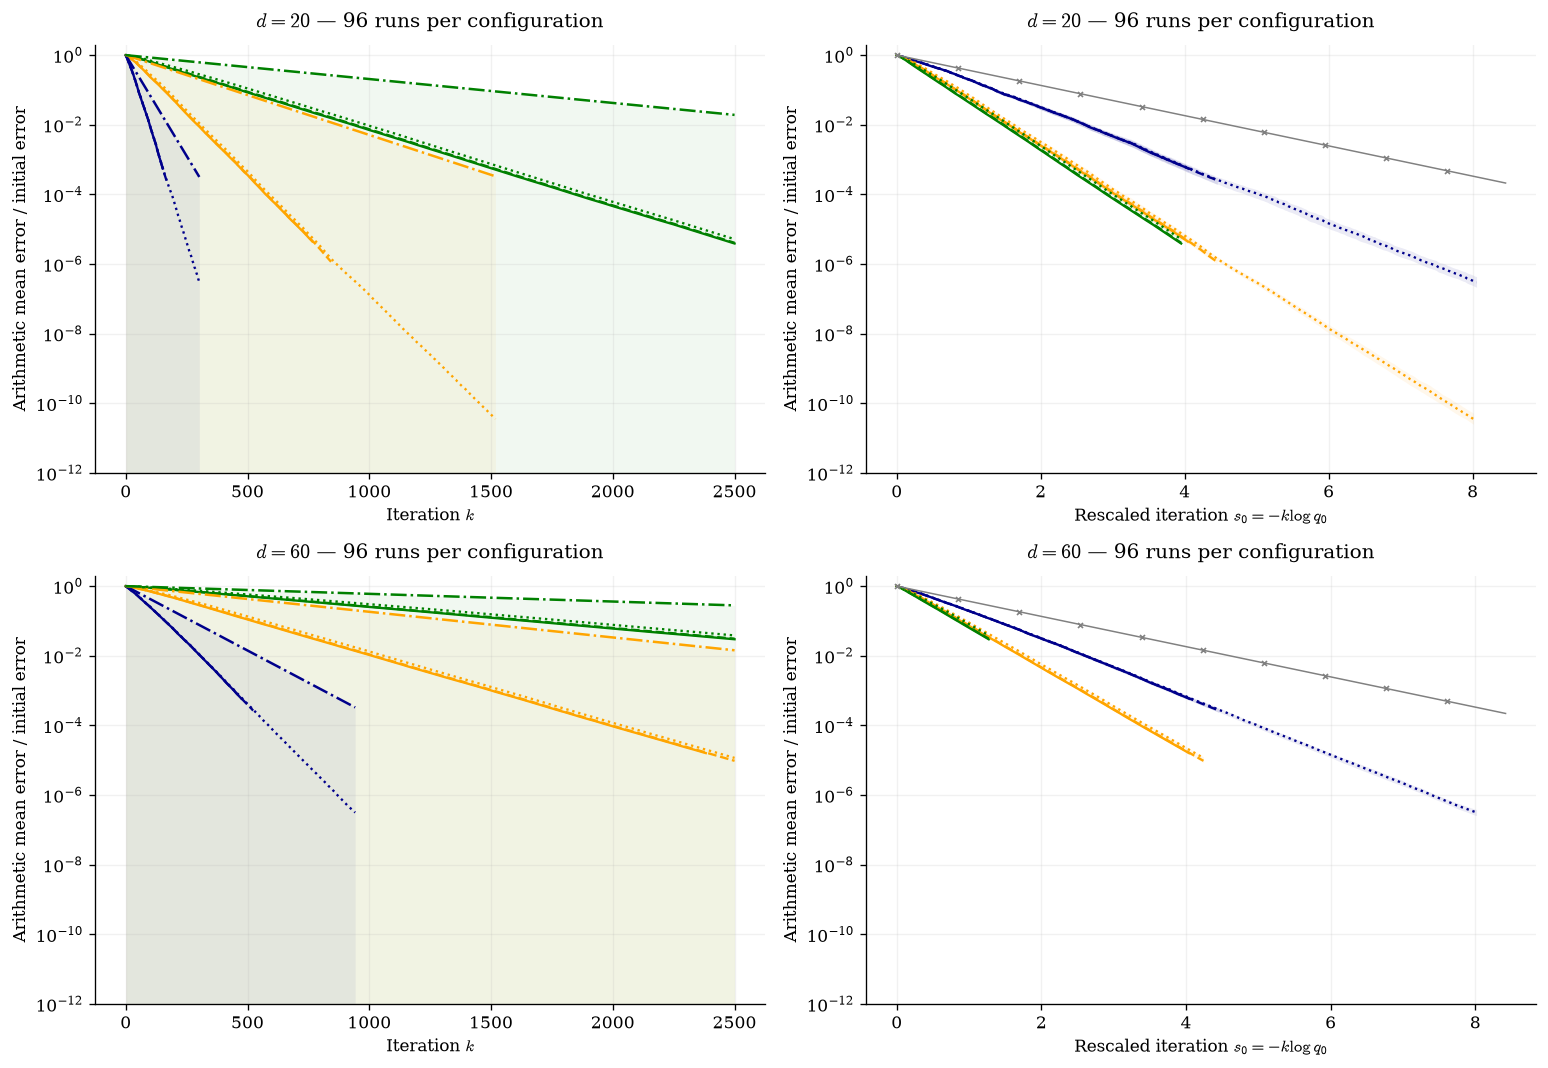

In [18]:
# Reference layout: dimensions by rows, ordinary/rescaled iteration by columns.
ETA_STYLES = dict(zip(ETAS, ['-', '--', ':']))
from matplotlib.patches import Patch
fig, axes = plt.subplots(len(cfg['dimensions']),2,
    figsize=(13,4.5*len(cfg['dimensions'])),squeeze=False)
PLOT_FLOOR = 1e-12
for row,d in enumerate(cfg['dimensions']):
    items = [x for x in experiments if x['d']==d]
    for x in items:
        k,c,eta = x['k'],x['constants'],x['eta']
        color,style = gap_colors[x['gap']],ETA_STYLES[eta]
        axes[row,0].semilogy(k,x['mean'],color=color,linestyle=style,linewidth=1.4)
        logq0 = np.log1p(-c['delta']/((d-1)*c['width']))
        s = -k*logq0
        axes[row,1].semilogy(s,x['mean'],color=color,linestyle=style,linewidth=1.4)
        axes[row,1].fill_between(s,x['low'],x['high'],color=color,alpha=.08,linewidth=0)

    # Limiting local reference as eta -> 0; not an upper bound for finite-error starts.
    for gap,color in gap_colors.items():
        group = [x for x in items if x['gap']==gap]
        c = group[0]['constants']
        logq0 = np.log1p(-c['delta']/((d-1)*c['width']))
        kref = np.linspace(0,max(x['k'][-1] for x in group),500)
        reference = np.exp(logq0*kref)
        axes[row,0].fill_between(kref,PLOT_FLOOR,reference,color=color,
                                 alpha=.055,linewidth=0,zorder=0)
        axes[row,0].semilogy(kref,reference,color=color,
                             linestyle='-.',linewidth=1.5,zorder=3)
    sref = np.linspace(0,max(axes[row,1].get_xlim()[1],.01),200)
    axes[row,1].semilogy(sref,np.exp(-sref),color='gray',marker='x',
                         markevery=20,markersize=3,linewidth=.9)
    for ax in axes[row]:
        ax.set(title=f'$d={d}$ — {cfg["runs"]} runs per configuration',
               ylabel='Arithmetic mean error / initial error',ylim=(PLOT_FLOOR,2))
    base = [Line2D([],[],color=color,label=rf'$g={g:g}$') for g,color in gap_colors.items()]
    base += [Line2D([],[],color='.3',linestyle=ETA_STYLES[eta],
                    label=rf'$\eta={eta:g}$') for eta in ETAS]
    axes[row,0].set_xlabel('Iteration $k$')
    axes[row,1].set_xlabel(r'Rescaled iteration $s_0=-k\log q_0$')
fig.tight_layout()
fig.savefig(OUT / f'local_convergence_{ETA_TAG}.pdf')
fig.savefig(OUT / f'local_convergence_{ETA_TAG}.png',dpi=180)
plt.show()